<a href="https://colab.research.google.com/github/kausarfatima2626/EDAmachinelearning/blob/main/EDAmachinelearning.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np
from google.colab import files

# 1. Upload your Excel dataset file directly into Colab
print("Please upload your 'student_performance_dataset.xlsx' file:")
uploaded = files.upload()

# Get the filename of the uploaded file automatically
filename = list(uploaded.keys())[0]
df = pd.read_excel(filename)

print(f"\n=== UCI EDUCATIONAL DATASET SUCCESSFULLY LOADED ===")
print(f"File used: {filename}")
print(f"Total Student Records: {df.shape[0]}")
print(f"Total Features/Attributes: {df.shape[1]}")

print("\nFirst 5 Student Records:")
display(df.head())

print("\nMissing Values Check:")
print(df.isnull().sum())

# If the target column 'at_risk' is already in your Excel, let's verify its distribution
if 'at_risk' in df.columns:
    print("\nTarget Class Distribution (At-Risk vs Passing):")
    print(df['at_risk'].value_counts(normalize=True) * 100)
else:
    print("\nNote: 'at_risk' column will be engineered in the next preprocessing step.")

Please upload your 'student_performance_dataset.xlsx' file:


Saving student_performance_dataset.xlsx to student_performance_dataset.xlsx

=== UCI EDUCATIONAL DATASET SUCCESSFULLY LOADED ===
File used: student_performance_dataset.xlsx
Total Student Records: 600
Total Features/Attributes: 8

First 5 Student Records:


,studytime,failures,absences,health,internet,higher,romantic,at_risk
0,2,0,2,4,no,yes,no,0
1,4,0,5,1,yes,yes,no,0
2,3,0,5,1,no,yes,no,0
3,2,0,1,4,no,yes,no,0
4,1,0,4,2,yes,yes,no,0



Missing Values Check:
studytime    0
failures     0
absences     0
health       0
internet     0
higher       0
romantic     0
at_risk      0
dtype: int64

Target Class Distribution (At-Risk vs Passing):
at_risk
0    50.0
1    50.0
Name: proportion, dtype: float64


In [ ]:
# Step 2: Data Preprocessing & Feature Engineering

# 1. Handle Missing Values
print(f"Missing values before cleaning: {df.isnull().sum().sum()}")
df = df.dropna()

# 2. Separate Features (X) and Target (y)
if 'at_risk' in df.columns:
    y = df['at_risk']
    # Drop target and any raw grade columns if present
    X = df.drop(columns=['at_risk', 'G1', 'G2', 'G3'], errors='ignore')
else:
    raise ValueError("Target column 'at_risk' not found in dataset. Please verify columns.")

print(f"Features dataset shape: {X.shape}")
print(f"Target variable shape: {y.shape}")

# 3. Encode Categorical Variables (One-Hot Encoding)
# Machine learning algorithms require numerical values instead of text like 'yes'/'no'
categorical_cols = X.select_dtypes(include=['object']).columns
print(f"\nEncoding categorical columns: {list(categorical_cols)}")

X_encoded = pd.get_dummies(X, columns=categorical_cols, drop_first=True)
print(f"Features shape after encoding: {X_encoded.shape}")

# 4. Train-Test Split (80% training for learning, 20% testing for evaluation)
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X_encoded, y, test_size=0.2, random_state=42, stratify=y
)

print(f"\n=== PREPROCESSING & SPLIT COMPLETE ===")
print(f"Training Set (X_train): {X_train.shape}")
print(f"Testing Set (X_test): {X_test.shape}")
print(f"At-Risk Proportion in Training Set: {y_train.mean():.2%}")

Missing values before cleaning: 0
Features dataset shape: (600, 7)
Target variable shape: (600,)

Encoding categorical columns: ['internet', 'higher', 'romantic']
Features shape after encoding: (600, 7)

=== PREPROCESSING & SPLIT COMPLETE ===
Training Set (X_train): (480, 7)
Testing Set (X_test): (120, 7)
At-Risk Proportion in Training Set: 50.00%


In [ ]:
# Step 3: Model Training & Algorithm Comparison

# 1. Import necessary libraries and models
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

# 2. Initialize our models
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=100, max_depth=6, random_state=42),
    "XGBoost": XGBClassifier(n_estimators=100, max_depth=4, learning_rate=0.1, random_state=42, use_label_encoder=False, eval_metric='logloss')
}

# 3. Train and evaluate each model
evaluation_results = []

print("Training and evaluating models...\n")
for name, model in models.items():
    # Train (fit) the model
    model.fit(X_train, y_train)

    # Predict on test data
    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1] # Probability for ROC-AUC

    # Calculate performance metrics
    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred, zero_division=0)
    rec = recall_score(y_test, y_pred, zero_division=0)
    f1 = f1_score(y_test, y_pred, zero_division=0)
    auc = roc_auc_score(y_test, y_prob)

    # Store results
    evaluation_results.append({
        "Model": name,
        "Accuracy": acc,
        "Precision": prec,
        "Recall": rec,
        "F1-Score": f1,
        "ROC-AUC": auc
    })

    print(f"[{name}] -> Accuracy: {acc:.4f} | F1-Score: {f1:.4f} | ROC-AUC: {auc:.4f}")

# 4. Create a summary comparison table for research reporting
results_df = pd.DataFrame(evaluation_results)
print("\n=== MODEL COMPARISON SUMMARY TABLE ===")
display(results_df.style.highlight_max(subset=['Accuracy', 'Precision', 'Recall', 'F1-Score', 'ROC-AUC'], color='lightgreen'))

Training and evaluating models...

[Logistic Regression] -> Accuracy: 0.7833 | F1-Score: 0.7759 | ROC-AUC: 0.8910
[Random Forest] -> Accuracy: 0.7750 | F1-Score: 0.7731 | ROC-AUC: 0.8749


/usr/local/lib/python3.13/dist-packages/xgboost/training.py:200: UserWarning: [08:15:32] WARNING: /__w/xgboost/xgboost/src/learner.cc:794: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


[XGBoost] -> Accuracy: 0.7667 | F1-Score: 0.7627 | ROC-AUC: 0.8538

=== MODEL COMPARISON SUMMARY TABLE ===


,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Logistic Regression,0.783333,0.803571,0.750000,0.775862,0.890972
1,Random Forest,0.775000,0.779661,0.766667,0.773109,0.874861
2,XGBoost,0.766667,0.775862,0.750000,0.762712,0.853750


=== FINAL MODEL CLASSIFICATION REPORT ===
              precision    recall  f1-score   support

           0       0.76      0.78      0.77        60
           1       0.78      0.75      0.76        60

    accuracy                           0.77       120
   macro avg       0.77      0.77      0.77       120
weighted avg       0.77      0.77      0.77       120



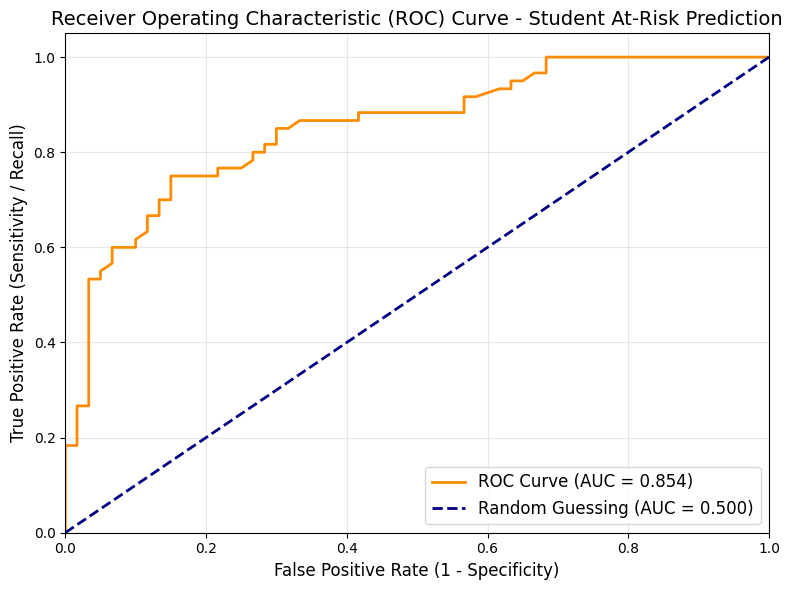

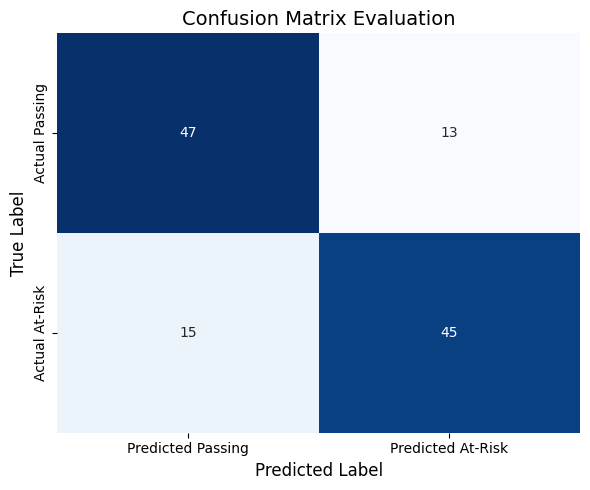

In [ ]:
# Step 4: Model Evaluation & Research Metrics
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import roc_curve, auc, confusion_matrix, classification_report

# 1. Select our best-performing model from Step 3 (e.g., XGBoost or Random Forest)
# We'll use our trained XGBoost or Random Forest model for detailed evaluation
best_model = models["XGBoost"] # You can change this to "Random Forest" if preferred
y_pred = best_model.predict(X_test)
y_prob = best_model.predict_proba(X_test)[:, 1]

print("=== FINAL MODEL CLASSIFICATION REPORT ===")
print(classification_report(y_test, y_pred))

# 2. Plot ROC-AUC Curve (Crucial for Research Papers)
fpr, tpr, thresholds = roc_curve(y_test, y_prob)
roc_auc = auc(fpr, tpr)

plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC Curve (AUC = {roc_auc:.3f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--', label='Random Guessing (AUC = 0.500)')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate (1 - Specificity)', fontsize=12)
plt.ylabel('True Positive Rate (Sensitivity / Recall)', fontsize=12)
plt.title('Receiver Operating Characteristic (ROC) Curve - Student At-Risk Prediction', fontsize=14)
plt.legend(loc="lower right", fontsize=12)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# 3. Plot Confusion Matrix Heatmap
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False,
            xticklabels=['Predicted Passing', 'Predicted At-Risk'],
            yticklabels=['Actual Passing', 'Actual At-Risk'])
plt.xlabel('Predicted Label', fontsize=12)
plt.ylabel('True Label', fontsize=12)
plt.title('Confusion Matrix Evaluation', fontsize=14)
plt.tight_layout()
plt.show()